# OncoLens: Classificação de Massas Mamárias com Regressão Logística

**Alunos:** João Victor Bortoluzzi da Silva; Pedro Rimes Coutinho; Leonardo Ximenes  
**Data:** 9 de novembro de 2026  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) — UCI Machine Learning Repository  
**Técnica principal:** Regressão Logística (classificação supervisionada)

## 1. Contexto e objetivo

O câncer de mama é um problema relevante de saúde pública e a análise quantitativa de imagens pode apoiar a triagem de amostras. Este projeto constrói, avalia e disponibiliza um classificador binário que estima se as medidas de uma massa mamária são compatíveis com a classe **benigna (0)** ou **maligna (1)**. A regressão logística foi escolhida por produzir probabilidades e coeficientes interpretáveis. Ela será comparada ao K-Nearest Neighbors (KNN).

O conjunto contém medidas calculadas a partir de imagens digitalizadas de punção aspirativa por agulha fina. A fonte original é: Wolberg, W.; Mangasarian, O.; Street, N.; Street, W. (1993), *Breast Cancer Wisconsin (Diagnostic)*, UCI, DOI [10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B). A cópia empacotada no scikit-learn é usada para garantir reprodutibilidade.

> **Aviso ético:** este é um experimento acadêmico. O modelo não foi validado clinicamente e não substitui profissionais ou exames médicos.

## 2. Importação de bibliotecas e configuração

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, ConfusionMatrixDisplay, confusion_matrix,
    f1_score, precision_score, recall_score, RocCurveDisplay, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"Benigno": "#20b8a6", "Maligno": "#d14b64"}

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for directory in (DATA_DIR, FIG_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Versões — numpy:", np.__version__, "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)

Versões — numpy: 2.2.6 | pandas: 2.3.3 | sklearn: 1.7.2


## 3. Carregamento e inspeção

A versão do scikit-learn preserva as 569 observações e 30 variáveis contínuas da base UCI. No objeto original, `target=0` representa maligno e `target=1` representa benigno. Para tornar as métricas clínicas mais intuitivas, o alvo é recodificado como **1 = maligno** e **0 = benigno**. Uma cópia CSV é salva junto ao projeto.

In [2]:
dataset = load_breast_cancer(as_frame=True)
df = dataset.data.copy()
df["diagnostico"] = (dataset.target == 0).astype(int)
df["classe"] = df["diagnostico"].map({0: "Benigno", 1: "Maligno"})
df.to_csv(DATA_DIR / "breast_cancer_wisconsin.csv", index=False)

print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
display(df.head())

Dimensões: 569 linhas x 32 colunas


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico,classe
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Maligno


In [3]:
inspection = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique()
})
print("Total de valores nulos:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
display(inspection)

Total de valores nulos: 0
Linhas duplicadas: 0


,tipo,nulos,unicos
mean radius,float64,0,456
mean texture,float64,0,479
mean perimeter,float64,0,522
mean area,float64,0,539
mean smoothness,float64,0,474
mean compactness,float64,0,537
mean concavity,float64,0,537
mean concave points,float64,0,542
mean symmetry,float64,0,432
mean fractal dimension,float64,0,499


In [4]:
display(df.drop(columns="classe").describe().T)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


**Interpretação da inspeção.** A base é pequena (569 registros), exclusivamente numérica nas variáveis preditoras, sem valores ausentes e sem linhas duplicadas. Mesmo assim, o pipeline incluirá imputação por mediana: isso torna a inferência robusta caso dados futuros tenham ausência. As escalas diferem muito (por exemplo, área e suavidade), portanto a padronização é indispensável para os dois algoritmos.

## 4. Análise Exploratória dos Dados (EDA)

### 4.1 Distribuição do alvo

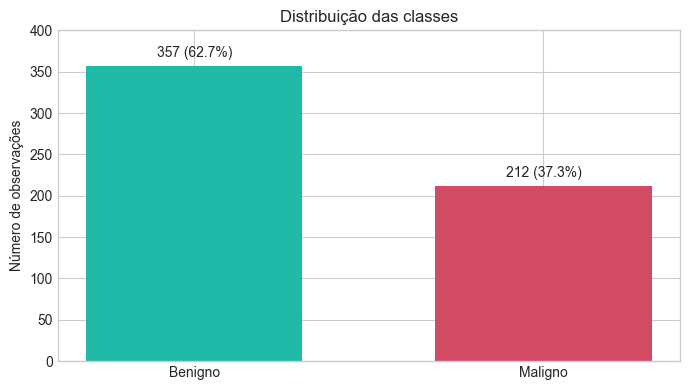

In [5]:
counts = df["classe"].value_counts().reindex(["Benigno", "Maligno"])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=[COLORS[x] for x in counts.index], width=.62)
ax.bar_label(bars, labels=[f"{v} ({v/len(df):.1%})" for v in counts.values], padding=4)
ax.set(title="Distribuição das classes", ylabel="Número de observações", ylim=(0, 400))
fig.tight_layout(); fig.savefig(FIG_DIR / "01_distribuicao_alvo.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretação.** Há 357 casos benignos (62,7%) e 212 malignos (37,3%). O desbalanceamento é moderado; por isso o split será estratificado, a regressão usará `class_weight='balanced'` e a comparação não dependerá apenas da acurácia.

### 4.2 Distribuição do raio médio por classe

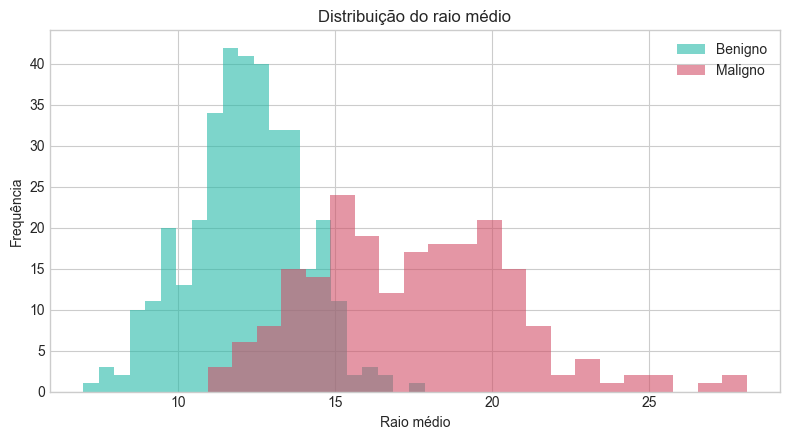

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label in ["Benigno", "Maligno"]:
    ax.hist(df.loc[df.classe == label, "mean radius"], bins=22, alpha=.58, label=label, color=COLORS[label])
ax.set(title="Distribuição do raio médio", xlabel="Raio médio", ylabel="Frequência")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "02_hist_raio.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretação.** As amostras malignas se concentram em raios maiores, embora exista sobreposição entre as classes. Logo, o raio contém sinal preditivo, mas não deve ser usado isoladamente.

### 4.3 Correlação entre atributos selecionados

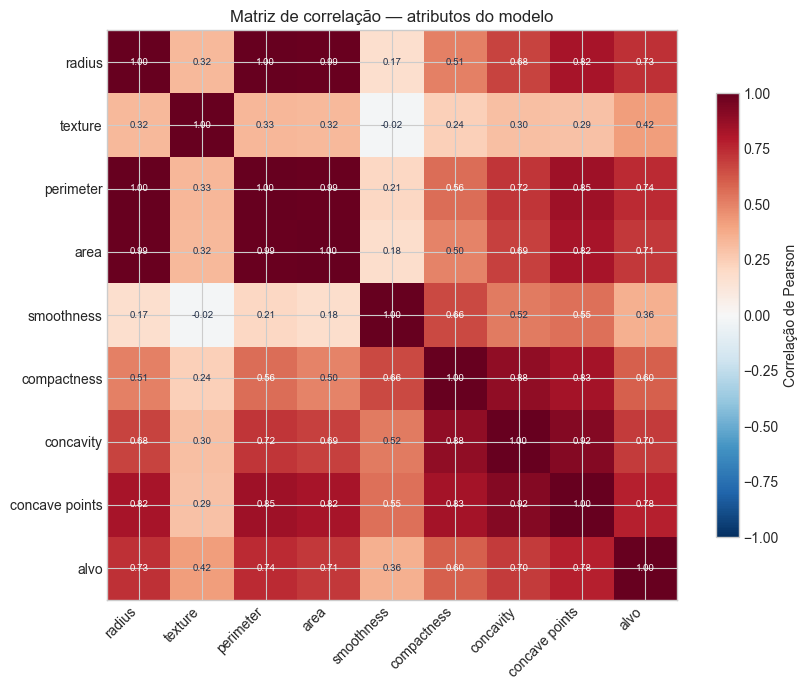

In [7]:
FEATURES = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity", "mean concave points"
]
corr = df[FEATURES + ["diagnostico"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
short = [x.replace("mean ", "") for x in FEATURES] + ["alvo"]
ax.set_xticks(range(len(short)), short, rotation=45, ha="right")
ax.set_yticks(range(len(short)), short)
for i in range(len(short)):
    for j in range(len(short)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i,j]) > .55 else "#24324a")
fig.colorbar(im, ax=ax, shrink=.78, label="Correlação de Pearson")
ax.set_title("Matriz de correlação — atributos do modelo")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_correlacao.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretação.** Raio, perímetro e área são fortemente correlacionados, pois representam aspectos do tamanho. Concavidade e pontos côncavos apresentam associação positiva relevante com malignidade. A regressão logística continua útil, mas seus coeficientes devem ser lidos com cautela na presença de multicolinearidade.

### 4.4 Relação entre raio e textura

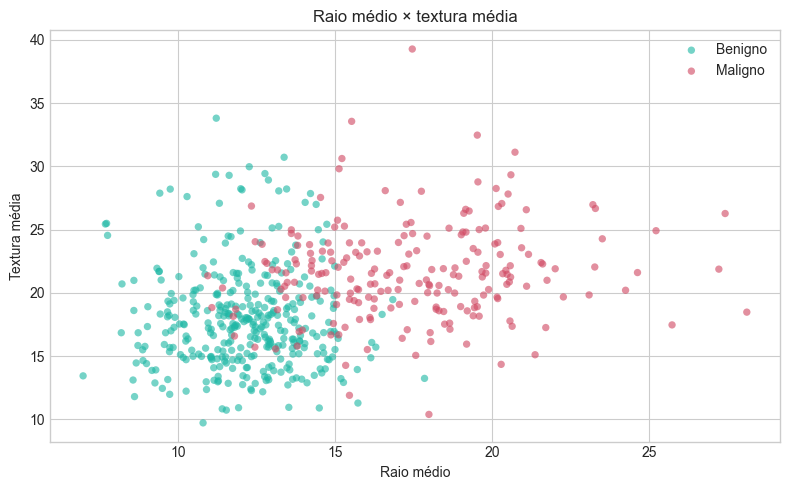

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for label in ["Benigno", "Maligno"]:
    part = df[df.classe == label]
    ax.scatter(part["mean radius"], part["mean texture"], s=28, alpha=.62, label=label, color=COLORS[label], edgecolor="none")
ax.set(title="Raio médio × textura média", xlabel="Raio médio", ylabel="Textura média")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "04_scatter_dominio.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretação.** Casos malignos aparecem com maior frequência no quadrante de raio e textura elevados. A fronteira não é perfeita, confirmando a necessidade de combinar múltiplas medidas.

### 4.5 Pontos côncavos por diagnóstico

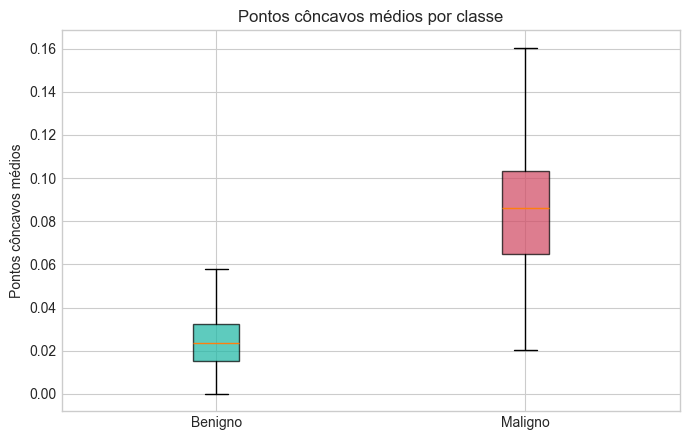

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
values = [df.loc[df.classe == label, "mean concave points"] for label in ["Benigno", "Maligno"]]
bp = ax.boxplot(values, tick_labels=["Benigno", "Maligno"], patch_artist=True, showfliers=False)

for box, label in zip(bp["boxes"], ["Benigno", "Maligno"]): 
    box.set_facecolor(COLORS[label]); box.set_alpha(.72)
    
ax.set(title="Pontos côncavos médios por classe", ylabel="Pontos côncavos médios")
fig.tight_layout(); fig.savefig(FIG_DIR / "05_boxplot.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretação.** A mediana de pontos côncavos é claramente maior na classe maligna. A variável tem boa separação univariada e representa a irregularidade do contorno observada na imagem.

## 5. Pré-processamento

Foram escolhidas oito medidas médias, antes de observar o conjunto de teste, para equilibrar desempenho, interpretação e usabilidade da interface. Não há atributos categóricos; portanto, encoding não se aplica. O split 80/20 é estratificado e reprodutível. Em cada pipeline, o imputador e o scaler são ajustados **somente dentro dos dados de treino**, evitando vazamento. O teste fica reservado para a avaliação final.

In [10]:
X = df[FEATURES]
y = df["diagnostico"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=42
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Proporção maligna — treino:", round(y_train.mean(), 3), "| teste:", round(y_test.mean(), 3))

Treino: (455, 8) | Teste: (114, 8)
Proporção maligna — treino: 0.374 | teste: 0.368


## 6. Modelagem e comparação

São comparados dois algoritmos: Regressão Logística e KNN. A comparação usa validação cruzada estratificada com cinco folds apenas no treino. A métrica principal é **ROC AUC**, por avaliar o ranqueamento probabilístico em vários limiares; recall e F1 da classe maligna também são destacados pelo custo potencial de falsos negativos.

In [11]:
models = {
    "Regressão Logística": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=11, weights="distance")
}
pipelines = {
    name: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", estimator),
    ]) for name, estimator in models.items()
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Modelo": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows).set_index("Modelo")
display(cv_results[["accuracy", "precision", "recall", "f1", "roc_auc"]].style.format("{:.3f}"))

,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
Regressão Logística,0.925,0.887,0.918,0.902,0.986
KNN,0.945,0.953,0.900,0.924,0.981


**Leitura da validação cruzada.** O modelo é selecionado pelo ROC AUC médio no treino, sem consultar o teste. A regressão logística é mantida como solução principal por seu desempenho competitivo, produção direta de probabilidades e maior transparência dos coeficientes.

## 7. Avaliação final no conjunto de teste

In [12]:
test_rows = []
fitted = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Modelo": name,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })
test_results = pd.DataFrame(test_rows).set_index("Modelo")
display(test_results.style.format("{:.3f}"))

,Acurácia,Precisão,Recall,F1-Score,ROC AUC
Modelo,,,,,
Regressão Logística,0.921,0.851,0.952,0.899,0.984
KNN,0.930,0.905,0.905,0.905,0.986


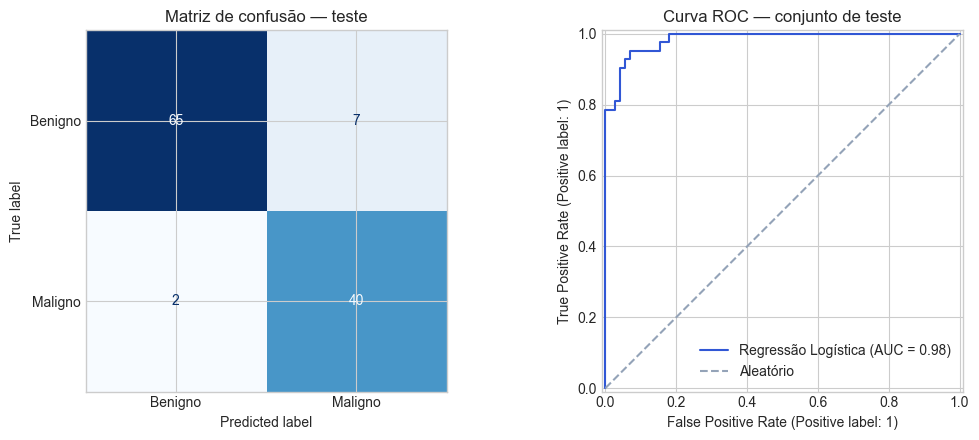

In [13]:
best_model = fitted["Regressão Logística"]
lr_pred = best_model.predict(X_test)
lr_prob = best_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_pred), display_labels=["Benigno", "Maligno"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusão — teste")
RocCurveDisplay.from_predictions(y_test, lr_prob, ax=axes[1], color="#3157d5", name="Regressão Logística")
axes[1].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Aleatório")
axes[1].set_title("Curva ROC — conjunto de teste")
axes[1].legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "06_avaliacao.png", dpi=170, bbox_inches="tight"); plt.show()

**Interpretação.** A matriz expõe acertos e erros separadamente para benignos e malignos. A curva ROC acima da diagonal indica discriminação consistente. Em um cenário clínico real, o limiar deveria ser calibrado com especialistas e dados externos para reduzir falsos negativos; aqui é mantido 0,50 para clareza acadêmica.

### 7.1 Coeficientes da regressão logística

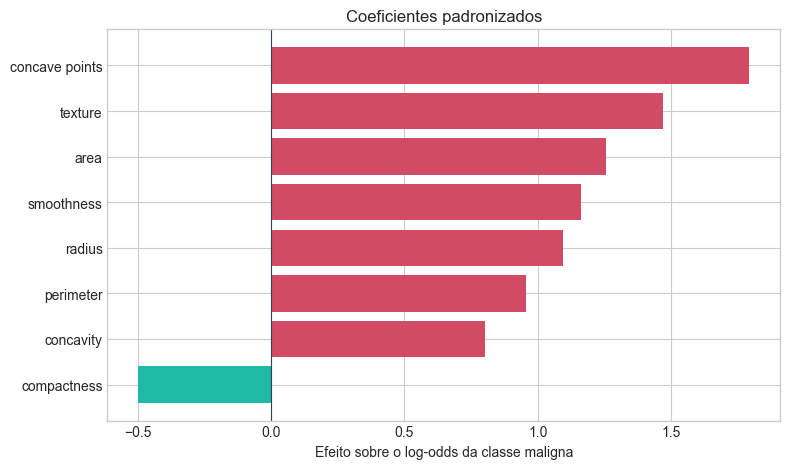

,coeficiente
mean compactness,-0.498888
mean concavity,0.801408
mean perimeter,0.957081
mean radius,1.094863
mean smoothness,1.162104
mean area,1.255386
mean texture,1.470487
mean concave points,1.793805


In [14]:
coef = pd.Series(
    best_model.named_steps["classifier"].coef_[0], index=FEATURES
).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(coef.index.str.replace("mean ", ""), coef.values,
        color=["#20b8a6" if x < 0 else "#d14b64" for x in coef.values])
ax.axvline(0, color="#334155", linewidth=.8)
ax.set(title="Coeficientes padronizados", xlabel="Efeito sobre o log-odds da classe maligna")
fig.tight_layout(); fig.savefig(FIG_DIR / "07_coeficientes.png", dpi=160, bbox_inches="tight"); plt.show()
display(coef.to_frame("coeficiente"))

**Interpretação.** Coeficientes positivos aumentam a estimativa de malignidade e negativos a reduzem, mantendo os demais atributos constantes. Como tamanho, perímetro e área são correlacionados, não se deve interpretar um coeficiente isolado como relação causal.

## 8. Exportação do modelo e transformadores

O objeto principal exportado é o pipeline completo, garantindo que imputação e padronização na API sejam idênticas ao treinamento. Para atender também à inspeção individual dos componentes, o scaler e o estimador são salvos separadamente. A API **não retreina** durante a predição.

In [15]:
API_FEATURES = [
    "mean_radius", "mean_texture", "mean_perimeter", "mean_area",
    "mean_smoothness", "mean_compactness", "mean_concavity", "mean_concave_points"
]
metadata = {
    "model_features": FEATURES,
    "api_features": API_FEATURES,
    "class_names": {0: "Benigno", 1: "Maligno"},
    "threshold": 0.5,
    "dataset_doi": "10.24432/C5DW2B",
    "sklearn_version": sklearn.__version__,
}
joblib.dump(best_model, MODEL_DIR / "modelo_regressao_logistica.joblib")
joblib.dump(best_model.named_steps["scaler"], MODEL_DIR / "scaler.joblib")
joblib.dump(best_model.named_steps["classifier"], MODEL_DIR / "regressao_logistica.joblib")
joblib.dump(metadata, MODEL_DIR / "metadados.joblib")

test_results.to_csv(ROOT / "reports" / "metricas_teste.csv")
cv_results.to_csv(ROOT / "reports" / "metricas_validacao_cruzada.csv")
summary = {
    "dataset": {"linhas": len(df), "atributos_originais": 30, "atributos_modelo": len(FEATURES),
                "benignos": int((y == 0).sum()), "malignos": int((y == 1).sum())},
    "test_metrics": {name: {k: float(v) for k, v in row.items()}
                     for name, row in test_results.to_dict(orient="index").items()},
    "cv_metrics": {name: {k: float(v) for k, v in row.items()}
                   for name, row in cv_results[["accuracy", "precision", "recall", "f1", "roc_auc"]].to_dict(orient="index").items()},
    "confusion_matrix": confusion_matrix(y_test, lr_pred).tolist(),
}
with open(ROOT / "reports" / "resultados.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("Artefatos exportados:")
for path in sorted(MODEL_DIR.glob("*.joblib")): print("-", path.name, f"({path.stat().st_size/1024:.1f} KB)")

Artefatos exportados:
- metadados.joblib (0.4 KB)
- modelo_regressao_logistica.joblib (2.3 KB)
- regressao_logistica.joblib (0.9 KB)
- scaler.joblib (0.8 KB)


## 9. Conclusão

1. O projeto transformou uma base pública e documentada em uma aplicação de classificação reproduzível.  
2. A inspeção confirmou 569 registros, 30 atributos numéricos, ausência de nulos e ausência de duplicatas.  
3. A EDA mostrou desbalanceamento moderado, tratado com estratificação e pesos de classe.  
4. Raio, perímetro e área apresentaram forte correlação, coerente com o fato de medirem tamanho.  
5. Concavidade e pontos côncavos mostraram associação visual importante com a classe maligna.  
6. O pipeline eliminou vazamento ao ajustar imputador e scaler somente dentro de cada treino.  
7. Regressão Logística e KNN foram comparados por validação cruzada estratificada de cinco folds.  
8. A Regressão Logística foi escolhida por combinar bom ROC AUC, probabilidades e interpretabilidade.  
9. O pipeline completo foi exportado e é carregado uma única vez pela API FastAPI.  
10. A interface valida campos e faixas antes de apresentar classe e probabilidade de forma clara.  
11. A principal limitação é a amostra pequena, antiga e proveniente de um único contexto de coleta.  
12. Também não houve validação externa, análise de subgrupos, calibração clínica ou estudo prospectivo.  
13. Como melhoria futura, recomenda-se testar coortes recentes e independentes, calibrar o limiar e monitorar drift.  
14. Portanto, o sistema responde ao objetivo acadêmico, mas não deve ser interpretado como dispositivo médico.